In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("GPU chưa được kích hoạt trên Colab!")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
# ==================================================================================
# CELL MOUNT DRIVE DÙNG CHUNG — giữ NGUYÊN VĂN ở mọi notebook experiment
# (Baseline, Label Flipping, Backdoor, Defense). Chỉ sửa khối CẤU HÌNH bên dưới,
# và phải sửa giống hệt nhau ở mọi notebook.
# ==================================================================================
import os
import sys
import json    # dùng ở các cell sau
import csv     # dùng ở các cell sau
import shutil
import subprocess
from pathlib import Path

# ------------------------------ CẤU HÌNH (cả nhóm dùng chung) ---------------------
SHARED_FOLDER_NAME = 'data-poisoning-shared'   # tên thư mục gốc trong Drive (mọi người đặt đúng tên này)
REPO_URL = 'https://github.com/qtrong0205/data-poisoning-research'                                  # URL GitHub của project; để trống = lấy code từ <thư mục gốc>/repo
REPO_BRANCH = 'backdoor'
LOCAL_PROJECT = Path('/content/data-poisoning-plantvillage')   # nơi chạy code (đĩa local của Colab, nhanh)
DRIVE_MOUNT = '/content/drive'
PIPELINES = ['baseline', 'label_flipping', 'backdoor', 'defenses']
# -----------------------------------------------------------------------------------

# 1. Mount Drive -----------------------------------------------------------------------
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount(DRIVE_MOUNT)
elif not Path(DRIVE_MOUNT).is_dir():
    raise RuntimeError('Cell này dành cho Google Colab (hoặc đặt DRIVE_MOUNT trỏ tới thư mục Drive).')

# 2. Tìm thư mục gốc dùng chung ----------------------------------------------------------
_candidates = []
if os.environ.get('DP_DRIVE_ROOT_OVERRIDE'):          # chỉ dùng khi muốn ép đường dẫn thủ công
    _candidates.append(Path(os.environ['DP_DRIVE_ROOT_OVERRIDE']))
_candidates.append(Path(DRIVE_MOUNT) / 'MyDrive' / SHARED_FOLDER_NAME)
_candidates.append(Path(DRIVE_MOUNT) / 'Shareddrives' / SHARED_FOLDER_NAME)
_candidates.extend(sorted(Path(DRIVE_MOUNT, 'Shareddrives').glob(f'*/{SHARED_FOLDER_NAME}')))
DRIVE_ROOT = next((c for c in _candidates if c.is_dir()), None)
if DRIVE_ROOT is None:
    raise FileNotFoundError(
        f'Không tìm thấy thư mục dùng chung "{SHARED_FOLDER_NAME}". Đã tìm ở:\n  - '
        + '\n  - '.join(str(c) for c in _candidates)
        + '\nCách khắc phục: mở thư mục được chia sẻ trong Drive (Shared with me), chuột phải '
          '"Add shortcut to Drive", chọn My Drive và giữ nguyên tên, rồi chạy lại cell này.'
    )

DRIVE_DATA = DRIVE_ROOT / 'data'
DRIVE_RESULTS = DRIVE_ROOT / 'results'
DRIVE_CHECKPOINTS = DRIVE_ROOT / 'checkpoints'

# 3. Bảo đảm cấu trúc thư mục (chỉ tạo thư mục còn thiếu, không xóa/ghi đè gì) -----------------
for _d in [DRIVE_DATA / 'plantvillage dataset', DRIVE_DATA / 'splits', DRIVE_DATA / 'samples',
           DRIVE_DATA / 'poisoned' / 'label_flipping', DRIVE_DATA / 'poisoned' / 'backdoor',
           *(DRIVE_RESULTS / p for p in PIPELINES), *(DRIVE_CHECKPOINTS / p for p in PIPELINES)]:
    _d.mkdir(parents=True, exist_ok=True)

# Kiểm tra quyền ghi (người chỉ có quyền xem sẽ không lưu được kết quả)
_probe = DRIVE_RESULTS / f'.write_test_{os.getpid()}'
try:
    _probe.write_text('ok')
    _probe.unlink()
except OSError as exc:
    raise PermissionError(
        f'Không ghi được vào {DRIVE_RESULTS}. Hãy nhờ chủ thư mục cấp quyền Editor. ({exc})') from exc


# 4. Lấy code về đĩa local ------------------------------------------------------------------
def _sh(cmd, secret=None):
    shown = ' '.join(cmd)
    if secret:
        shown = shown.replace(secret, '***')
    print('$', shown)
    done = subprocess.run(cmd, text=True, capture_output=True)
    out = (done.stdout + done.stderr).strip()
    if secret:
        out = out.replace(secret, '***')
    if out:
        print(out)
    if done.returncode != 0:
        raise RuntimeError(f'Lệnh thất bại (exit {done.returncode}).')


if REPO_URL:
    _url, _token = REPO_URL, None
    if _url.startswith('https://') and 'github.com' in _url:
        try:                                    # repo private: lưu token trong Colab Secrets với tên GITHUB_TOKEN
            from google.colab import userdata
            _token = userdata.get('GITHUB_TOKEN')
        except Exception:
            _token = None
        if _token:
            _url = _url.replace('https://', f'https://{_token}@', 1)
    if (LOCAL_PROJECT / '.git').is_dir():
        _sh(['git', '-C', str(LOCAL_PROJECT), 'pull', '--ff-only'], secret=_token)
    else:
        _sh(['git', 'clone', '--depth', '1', '--branch', REPO_BRANCH, _url, str(LOCAL_PROJECT)], secret=_token)
    CODE_SOURCE = f'GitHub {REPO_URL} ({REPO_BRANCH})'
else:
    _src = DRIVE_ROOT / 'repo'
    if not _src.is_dir():
        raise FileNotFoundError(
            f'Chưa có {_src}. Hãy upload code vào thư mục repo/ trong Drive dùng chung '
            '(chỉ code, không kèm data/results/checkpoints), hoặc điền REPO_URL.')
    _skip_anywhere = {'.git', '__pycache__', '.ipynb_checkpoints', 'results', 'checkpoints'}
    _skip_top = {'data', 'outputs', 'models'}

    def _ignore(directory, names):
        skip = {n for n in names if n in _skip_anywhere or n.endswith(('.pth', '.pt', '.onnx'))}
        if Path(directory) == _src:
            skip |= {n for n in names if n in _skip_top}
        return skip

    shutil.copytree(_src, LOCAL_PROJECT, dirs_exist_ok=True, ignore=_ignore)
    CODE_SOURCE = f'Drive: {_src}'

PROJECT_ROOT = LOCAL_PROJECT
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# 5. Nối các thư mục dữ liệu/kết quả/checkpoint của project vào Drive (symlink) ---------------
#    Code không cần sửa: đường dẫn tương đối trong project tự trỏ vào Drive.
LINKS = {
    'data/plantvillage dataset': DRIVE_DATA / 'plantvillage dataset',
    'data/splits': DRIVE_DATA / 'splits',
    'data/poisoned': DRIVE_DATA / 'poisoned',
    'data/samples': DRIVE_DATA / 'samples',
    'outputs': DRIVE_RESULTS,
    'models/checkpoints': DRIVE_CHECKPOINTS,
}
for _p in PIPELINES:
    LINKS[f'experiments/{_p}/results'] = DRIVE_RESULTS / _p
    LINKS[f'experiments/{_p}/checkpoints'] = DRIVE_CHECKPOINTS / _p


def _link(rel, target):
    path = PROJECT_ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.is_symlink():
        if Path(os.readlink(path)) == target:
            return 'OK'
        path.unlink()
    elif path.exists():
        if path.is_dir() and not any(path.iterdir()):
            path.rmdir()
        else:
            return 'BỎ QUA: đã có dữ liệu thật trong thư mục local, không ghi đè'
    os.symlink(target, path, target_is_directory=True)
    return 'OK'


_link_status = {rel: _link(rel, tgt) for rel, tgt in LINKS.items()}

# 6. Biến môi trường cho code mới (attack/defense) ---------------------------------------------
os.environ.update({
    'DP_DRIVE_ROOT': str(DRIVE_ROOT),
    'DP_DATA_ROOT': str(DRIVE_DATA),
    'DP_RESULTS_ROOT': str(DRIVE_RESULTS),
    'DP_CHECKPOINTS_ROOT': str(DRIVE_CHECKPOINTS),
})


def finish_session():
    """Gọi ở cuối phiên (hoặc trước khi bạn khác tiếp tục) để chắc chắn dữ liệu đã đồng bộ lên Drive."""
    if IN_COLAB:
        from google.colab import drive as _drive
        _drive.flush_and_unmount()
        print('Đã đồng bộ và ngắt kết nối Drive.')
    else:
        print('Không ở trong Colab: không cần đồng bộ.')


# 7. Tóm tắt -----------------------------------------------------------------------------------
print(f'Drive root : {DRIVE_ROOT}')
print(f'Code       : {PROJECT_ROOT}  <-  {CODE_SOURCE}')
print('Liên kết (project -> Drive):')
for _rel, _st in _link_status.items():
    print(f'  {_rel:<40} {_st}')
_raw = DRIVE_DATA / 'plantvillage dataset' / 'color'
_has = {
    'ảnh gốc (data/plantvillage dataset/color)': _raw.is_dir() and any(_raw.iterdir()),
    'manifest_train.csv': (DRIVE_DATA / 'splits' / 'manifest_train.csv').is_file(),
    'manifest_test.csv': (DRIVE_DATA / 'splits' / 'manifest_test.csv').is_file(),
    'class_to_idx.json': (DRIVE_DATA / 'splits' / 'class_to_idx.json').is_file(),
}
print('Dữ liệu dùng chung:')
for _name, _ok in _has.items():
    print(f'  {"CÓ   " if _ok else "THIẾU"} {_name}')
print('Quyền ghi: OK')

Mounted at /content/drive
$ git clone --depth 1 --branch backdoor https://github.com/qtrong0205/data-poisoning-research /content/data-poisoning-plantvillage
Cloning into '/content/data-poisoning-plantvillage'...
Drive root : /content/drive/MyDrive/data-poisoning-shared
Code       : /content/data-poisoning-plantvillage  <-  GitHub https://github.com/qtrong0205/data-poisoning-research (backdoor)
Liên kết (project -> Drive):
  data/plantvillage dataset                OK
  data/splits                              OK
  data/poisoned                            OK
  data/samples                             OK
  outputs                                  OK
  models/checkpoints                       OK
  experiments/baseline/results             OK
  experiments/baseline/checkpoints         OK
  experiments/label_flipping/results       OK
  experiments/label_flipping/checkpoints   OK
  experiments/backdoor/results             OK
  experiments/backdoor/checkpoints         OK
  experiments/defenses

In [3]:
# Kiểm tra các thư mục kết quả/checkpoint đã thật sự nối vào Drive (nếu không, kết quả sẽ MẤT khi hết phiên)
_bad = {rel: st for rel, st in _link_status.items() if st != 'OK'}
if _bad:
    raise RuntimeError(
        'Các thư mục sau chưa được nối vào Drive:\n'
        + '\n'.join(f'  {rel}: {st}' for rel, st in _bad.items())
        + '\nNguyên nhân thường gặp: thư mục đó vẫn còn file được commit trong repo (hãy git rm --cached '
          'và thêm vào .gitignore). Không chạy training khi lỗi này chưa được xử lý.')
print(f'Đã nối {len(_link_status)} thư mục của project vào Drive.')

Đã nối 14 thư mục của project vào Drive.


In [4]:
# Cài dependency, bỏ qua torch/torchvision/CUDA để không ghi đè PyTorch sẵn có của Colab
import re

SKIP_PACKAGES = {'torch', 'torchvision', 'torchaudio', 'triton'}
packages = []
for line in (PROJECT_ROOT / 'requirements.txt').read_text(encoding='utf-8').splitlines():
    item = line.strip()
    if not item or item.startswith(('#', '-')):
        continue
    name = re.split(r'[=<>!~;\[\s@]', item, maxsplit=1)[0].lower().replace('_', '-')
    if name in SKIP_PACKAGES or name.startswith('nvidia-'):
        continue
    packages.append(item)
if packages:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *packages], check=True)
print(f'Đã cài {len(packages)} package.')

Đã cài 13 package.


In [5]:
import torch
import torchvision
import yaml
import sklearn
import matplotlib
import importlib
import numpy as np
import pandas as pd
import PIL
from tqdm.auto import tqdm

print("Dependencies imported successfully!")


Dependencies imported successfully!


In [6]:
# Kiểm tra dữ liệu dùng chung. Notebook KHÔNG tự tải dataset hay tạo split:
# việc đó do người quản lý làm một lần (nhiều người cùng ghi vào Drive dùng chung sẽ gây lỗi).
import pandas as pd

split_dir = PROJECT_ROOT / 'data/splits'
for _name in ('manifest_train.csv', 'manifest_test.csv', 'class_to_idx.json'):
    if not (split_dir / _name).is_file():
        raise FileNotFoundError(f'Thiếu {split_dir / _name}. Hãy báo người quản lý chuẩn bị dữ liệu.')

# So số ảnh trong manifest với số file thật của từng lớp (nhanh, chỉ liệt kê thư mục)
_problems = []
for _split in ('train', 'test'):
    _df = pd.read_csv(split_dir / f'manifest_{_split}.csv')
    for _cls, _n in _df.groupby('class_name').size().items():
        _folder = split_dir / _split / _cls
        _have = sum(1 for e in os.scandir(_folder) if e.is_file()) if _folder.is_dir() else 0
        if _have < _n:
            _problems.append({'split': _split, 'class': _cls, 'manifest': int(_n), 'on_drive': _have})
if _problems:
    display(pd.DataFrame(_problems))
    raise FileNotFoundError(f'{len(_problems)} lớp thiếu ảnh trong data/splits (bảng trên). Báo người quản lý bổ sung trước khi train.')
print('data/splits đầy đủ so với manifest.')

data/splits đầy đủ so với manifest.


In [7]:
# Hàm chạy lệnh con và in log RA CELL NGAY KHI có (kể cả thanh tiến trình tqdm dùng ký tự \r).
# subprocess.run(...) trần không hiện log trong cell Colab, nên cell trông như bị "đóng băng".
import codecs
import os
import subprocess
import sys


def run_streaming(cmd, cwd=None):
    env = {**os.environ, 'PYTHONUNBUFFERED': '1'}
    proc = subprocess.Popen(cmd, cwd=cwd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    decoder = codecs.getincrementaldecoder('utf-8')('replace')   # không làm hỏng chữ có dấu bị cắt giữa chunk
    try:
        while True:
            chunk = proc.stdout.read1(4096)       # trả về ngay khi có dữ liệu, không chờ xuống dòng
            if not chunk:
                break
            sys.stdout.write(decoder.decode(chunk))
            sys.stdout.flush()
        sys.stdout.write(decoder.decode(b'', final=True))
    except BaseException:                         # bấm Stop trên Colab: dừng luôn tiến trình train, tránh chạy mồ côi
        proc.kill()
        proc.wait()
        raise
    code = proc.wait()
    if code != 0:
        raise subprocess.CalledProcessError(code, cmd)
    return code


# ---------------------------------------------------------------------------------
# Đọc hàng chục nghìn ảnh nhỏ trực tiếp từ Drive rất chậm và có thể đứng rất lâu (nhất là lần đọc đầu).
# Chép ảnh về đĩa local của Colab (song song) rồi train từ bản local. Kết quả/checkpoint vẫn ghi vào Drive.
# ---------------------------------------------------------------------------------
import shutil
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import pandas as pd

USE_LOCAL_SPLITS = True                       # False: đọc thẳng từ Drive (chậm)
LOCAL_SPLITS = Path('/content/splits_local')


def prepare_local_splits(only_subset, workers=32):
    if not USE_LOCAL_SPLITS:
        print('USE_LOCAL_SPLITS=False: đọc ảnh trực tiếp từ Drive.', flush=True)
        return
    src = DRIVE_DATA / 'splits'
    train = pd.read_csv(src / 'manifest_train.csv')
    if only_subset:
        train = train[train.in_subset == 1]
    test = pd.read_csv(src / 'manifest_test.csv')
    rels = list(train.rel_path) + list(test.rel_path)
    todo = [r for r in rels if not (LOCAL_SPLITS / r).is_file()]
    print(f'Chép {len(todo):,}/{len(rels):,} ảnh từ Drive về {LOCAL_SPLITS} (đã có sẵn {len(rels) - len(todo):,}).', flush=True)
    LOCAL_SPLITS.mkdir(parents=True, exist_ok=True)
    for name in ('manifest_train.csv', 'manifest_test.csv', 'class_to_idx.json'):
        shutil.copy2(src / name, LOCAL_SPLITS / name)

    def _copy(rel):
        dst = LOCAL_SPLITS / rel
        dst.parent.mkdir(parents=True, exist_ok=True)
        tmp = dst.with_name(dst.name + '.part')
        shutil.copyfile(src / rel, tmp)
        os.replace(tmp, dst)                  # ghi xong mới đổi tên: file dở dang không bị coi là đã chép

    t0, done = time.time(), 0
    with ThreadPoolExecutor(max_workers=workers) as pool:
        for _ in pool.map(_copy, todo):
            done += 1
            if done % 2000 == 0:
                print(f'  đã chép {done:,}/{len(todo):,} ({done / (time.time() - t0):.0f} ảnh/giây)', flush=True)
    print(f'Xong {len(todo):,} ảnh trong {time.time() - t0:.0f}s.', flush=True)

    link = PROJECT_ROOT / 'data/splits'
    if link.is_symlink():
        link.unlink()
    elif link.exists():
        raise RuntimeError(f'{link} là thư mục thật, không đổi sang bản local được.')
    link.symlink_to(LOCAL_SPLITS, target_is_directory=True)
    print(f'data/splits đang trỏ tới {LOCAL_SPLITS} (đĩa local).', flush=True)

In [8]:
# Output của backdoor nằm ở experiments/backdoor/<E-BDx_...>/{results,checkpoints,logs}
# (khác baseline), nên các symlink ở cell mount chưa phủ tới. Nối thêm vào Drive để kết quả không bị mất.
_bd_cfg = yaml.safe_load((PROJECT_ROOT / 'configs/attacks/backdoor/backdoor.yaml').read_text(encoding='utf-8'))

_bd_links = {}
for _eid, _exp in _bd_cfg['experiments'].items():
    _out = Path(_exp['output_dir'])
    _targets = {
        'results': DRIVE_RESULTS / 'backdoor' / _eid / 'results',
        'logs': DRIVE_RESULTS / 'backdoor' / _eid / 'logs',
        'checkpoints': DRIVE_CHECKPOINTS / 'backdoor' / _eid,
    }
    for _sub, _target in _targets.items():
        _target.mkdir(parents=True, exist_ok=True)
        _bd_links[f'{_out.as_posix()}/{_sub}'] = _target

_bd_status = {rel: _link(rel, tgt) for rel, tgt in _bd_links.items()}
_bd_bad = {rel: st for rel, st in _bd_status.items() if st != 'OK'}
if _bd_bad:
    raise RuntimeError(
        'Các thư mục output backdoor sau chưa được nối vào Drive:\n'
        + '\n'.join(f'  {rel}: {st}' for rel, st in _bd_bad.items())
        + '\nKhông chạy training khi lỗi này chưa được xử lý (kết quả sẽ mất khi hết phiên).')
for _rel, _st in _bd_status.items():
    print(f'  {_rel:<60} {_st}')
print(f'Đã nối {len(_bd_status)} thư mục output backdoor vào Drive.')


  experiments/backdoor/E-BD1_poisoning_rate/results            OK
  experiments/backdoor/E-BD1_poisoning_rate/logs               OK
  experiments/backdoor/E-BD1_poisoning_rate/checkpoints        OK
  experiments/backdoor/E-BD2_trigger_size/results              OK
  experiments/backdoor/E-BD2_trigger_size/logs                 OK
  experiments/backdoor/E-BD2_trigger_size/checkpoints          OK
  experiments/backdoor/E-BD3_trigger_position/results          OK
  experiments/backdoor/E-BD3_trigger_position/logs             OK
  experiments/backdoor/E-BD3_trigger_position/checkpoints      OK
  experiments/backdoor/E-BD4_confirm/results                   OK
  experiments/backdoor/E-BD4_confirm/logs                      OK
  experiments/backdoor/E-BD4_confirm/checkpoints               OK
Đã nối 12 thư mục output backdoor vào Drive.


In [9]:
# Chạy 1 experiment backdoor: kiểm tra config -> bỏ qua nếu mọi variant đã xong -> chép ảnh về local -> train
def run_backdoor_experiment(experiment_id):
    bd = importlib.reload(importlib.import_module('experiments.backdoor.experiment'))   # dùng lại hàm của experiment.py
    backdoor_cfg, dataset_cfg, baseline_cfg = bd.load_configs()

    try:
        exp = bd.validate_experiment(backdoor_cfg, dataset_cfg, baseline_cfg, experiment_id)
    except ValueError as exc:
        print(f'[{experiment_id}] CHƯA CHẠY ĐƯỢC: {exc}', flush=True)
        return

    variants = bd.get_experiment_variants(exp, backdoor_cfg['attack']['trigger'])
    pending = [v for v in variants if not bd.is_completed_run(experiment_id, exp, v)]
    print(f'[{experiment_id}] {exp.get("name")}: {len(variants)} variant, đã xong {len(variants) - len(pending)}, cần chạy {len(pending)}.', flush=True)
    if not pending:
        print(f'[{experiment_id}] Đã có kết quả hợp lệ trên Drive, bỏ qua training.', flush=True)
        return

    prepare_local_splits(only_subset=(exp['dataset_scope'] == 'subset'))
    print(f'[{experiment_id}] launching training subprocess...', flush=True)
    run_streaming(
        [sys.executable, '-u', '-m', 'experiments.backdoor.experiment', '--experiment', experiment_id],
        cwd=PROJECT_ROOT,
    )
    print(f'[{experiment_id}] subprocess completed.', flush=True)
    print(f'Results are stored in: {DRIVE_RESULTS / "backdoor" / experiment_id}')
    print(f'Checkpoints are stored in: {DRIVE_CHECKPOINTS / "backdoor" / experiment_id}')


In [10]:
# E-BD1: poisoning_rate_sweep
%cd /content/data-poisoning-plantvillage
run_backdoor_experiment('E-BD1')


/content
[E-BD1] poisoning_rate_sweep: 7 variant, đã xong 7, cần chạy 0.
[E-BD1] Đã có kết quả hợp lệ trên Drive, bỏ qua training.


## E-BD1 – Phân tích kết quả thí nghiệm ban đầu

E-BD1 khảo sát ảnh hưởng của poisoning rate đến hiệu quả backdoor attack. Các biến khác được giữ cố định: target label 10 (`Corn_(maize)___healthy`), trigger trắng 16×16 ở góc dưới bên phải, seed 42, subset 30%, MobileNetV2 pretrained với backbone đóng băng và 3 epochs.

### Kết quả thực nghiệm

| Poisoning rate | Clean Accuracy | Macro Precision | Macro Recall | Macro F1 | ASR |
|---:|---:|---:|---:|---:|---:|
| 1%  | 93.32% | 91.68% | 91.27% | 90.95% | 0.04% |
| 2%  | 92.90% | 91.21% | 90.58% | 90.12% | 0.47% |
| 5%  | 91.32% | 89.88% | 88.57% | 88.07% | 1.74% |
| 10% | 90.94% | 90.49% | 87.38% | 87.91% | 2.78% |
| 20% | 87.46% | 88.76% | 84.12% | 84.79% | 7.50% |
| 30% | 78.26% | 88.57% | 74.17% | 77.96% | 20.03% |
| 40% | 66.73% | 88.84% | 65.62% | 72.21% | 35.21% |

### Nhận xét ban đầu

- ASR tăng theo poisoning rate, từ 0.04% ở mức 1% lên 35.21% ở mức 40%.
- Clean Accuracy giảm từ 93.32% xuống 66.73%; Macro F1 giảm từ 90.95% xuống 72.21%.
- Ở poisoning rate cao, hiệu quả phân loại trên dữ liệu sạch suy giảm rõ rệt, trong khi ASR vẫn chưa đạt mức cao.
- Training accuracy cũng giảm khi poisoning rate tăng. Đây là accuracy trên tập train đã bị đổi nhãn, không phải clean training accuracy.

Kết quả cho thấy tăng số lượng poisoned samples làm ASR tăng, nhưng đồng thời gây ảnh hưởng đáng kể đến khả năng phân loại sạch. Cần phân tích thêm đặc điểm trigger và preprocessing để hiểu vì sao hiệu quả tấn công còn hạn chế.


In [11]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw
from IPython.display import display


PROJECT_ROOT = Path("/content/data-poisoning-plantvillage")

SPLIT_DIR = PROJECT_ROOT / "data" / "splits"

TRAIN_MANIFEST = SPLIT_DIR / "manifest_train.csv"

TRIGGER_SIZE = 16
TRIGGER_POSITION = "bottom_right"
TRIGGER_COLOR = (255, 255, 255)

TARGET_LABEL = 10
RANDOM_SEED = 42
NUM_SAMPLES = 12

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


train_df = pd.read_csv(TRAIN_MANIFEST)

train_df["image_path"] = train_df["rel_path"].apply(
    lambda x: SPLIT_DIR / x
)


train_df = train_df[
    train_df["image_path"].apply(lambda x: x.exists())
].reset_index(drop=True)

sampled_indices = []

for label, group in train_df.groupby("label"):
    sampled_indices.append(
        group.sample(
            n=min(1, len(group)),
            random_state=RANDOM_SEED
        ).index[0]
    )

remaining = NUM_SAMPLES - len(sampled_indices)

if remaining > 0:
    remaining_df = train_df.drop(index=sampled_indices)

    extra = remaining_df.sample(
        n=min(remaining, len(remaining_df)),
        random_state=RANDOM_SEED
    )

    sampled_indices.extend(extra.index.tolist())

sample_df = train_df.loc[sampled_indices].reset_index(drop=True)

print(f"Total training images: {len(train_df):,}")
print(f"Selected images: {len(sample_df)}")
display(sample_df[["rel_path", "label"]])

Total training images: 43,429
Selected images: 38


,rel_path,label
0,train/Apple___Apple_scab/61643f40-eb9a-4c6b-8d...,0
1,train/Apple___Black_rot/ee978e42-d36d-4bba-b0a...,1
2,train/Apple___Cedar_apple_rust/9b3023a6-f35a-4...,2
3,train/Apple___healthy/21b1f887-6f78-4da8-b676-...,3
4,train/Blueberry___healthy/36828f55-fc23-4083-a...,4
5,train/Cherry_(including_sour)___Powdery_mildew...,5
6,train/Cherry_(including_sour)___healthy/70cd29...,6
7,train/Corn_(maize)___Cercospora_leaf_spot Gray...,7
8,train/Corn_(maize)___Common_rust_/RS_Rust 1813...,8
9,train/Corn_(maize)___Northern_Leaf_Blight/bfd7...,9





In [12]:
def apply_trigger(
    image,
    size=TRIGGER_SIZE,
    position=TRIGGER_POSITION,
    color=TRIGGER_COLOR
):
    image = image.copy()

    width, height = image.size

    if position == "bottom_right":
        x1 = width - size
        y1 = height - size

    elif position == "top_left":
        x1, y1 = 0, 0

    elif position == "center":
        x1 = (width - size) // 2
        y1 = (height - size) // 2

    else:
        raise ValueError(f"Unsupported position: {position}")

    draw = ImageDraw.Draw(image)
    draw.rectangle(
        [x1, y1, x1 + size - 1, y1 + size - 1],
        fill=color
    )

    return image

fig, axes = plt.subplots(
    len(sample_df), 2,
    figsize=(9, len(sample_df) * 3)
)

for i, row in sample_df.iterrows():

    original = Image.open(row["image_path"]).convert("RGB")
    triggered = apply_trigger(original)

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f"Original - Label {row['label']}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(triggered)
    axes[i, 1].set_title("Triggered - White 16x16")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [13]:
def analyze_trigger_difference(image, triggered_image, size=TRIGGER_SIZE):
    original = np.asarray(image).astype(np.float32)
    triggered = np.asarray(triggered_image).astype(np.float32)

    height, width, _ = original.shape

    if TRIGGER_POSITION == "bottom_right":
        x1, y1 = width - size, height - size
    elif TRIGGER_POSITION == "top_left":
        x1, y1 = 0, 0
    elif TRIGGER_POSITION == "center":
        x1 = (width - size) // 2
        y1 = (height - size) // 2
    else:
        raise ValueError("Unsupported trigger position")

    original_patch = original[y1:y1+size, x1:x1+size]
    triggered_patch = triggered[y1:y1+size, x1:x1+size]

    diff = np.abs(triggered_patch - original_patch)

    # Pixel is considered near-white if all RGB channels >= 240.
    near_white_ratio = np.mean(
        np.all(original_patch >= 240, axis=2)
    )

    # Pixel is considered changed if at least one channel differs.
    changed_ratio = np.mean(
        np.any(diff > 0, axis=2)
    )

    mean_difference = diff.mean()

    return {
        "Background Near-white": near_white_ratio,
        "Changed Pixel Ratio": changed_ratio,
        "Mean Absolute Difference": mean_difference
    }


pixel_rows = []

for _, row in sample_df.iterrows():

    image = Image.open(row["image_path"]).convert("RGB")
    triggered = apply_trigger(image)

    metrics = analyze_trigger_difference(image, triggered)

    pixel_rows.append({
        "Class Label": row["label"],
        "Image": Path(row["rel_path"]).name,
        **metrics
    })

pixel_df = pd.DataFrame(pixel_rows)

display(
    pixel_df.style.format({
        "Background Near-white": "{:.2%}",
        "Changed Pixel Ratio": "{:.2%}",
        "Mean Absolute Difference": "{:.2f}"
    })
)

print("\nAverage metrics:")
display(
    pixel_df[
        [
            "Background Near-white",
            "Changed Pixel Ratio",
            "Mean Absolute Difference"
        ]
    ].mean().to_frame("Average")
)

,Class Label,Image,Background Near-white,Changed Pixel Ratio,Mean Absolute Difference
0,0,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Scab 3114.JPG,0.00%,100.00%,185.73
1,1,ee978e42-d36d-4bba-b0ac-fcc0eefaacd3___JR_FrgE.S 8665.JPG,0.00%,100.00%,110.58
2,2,9b3023a6-f35a-46b4-be98-022eb2ac42e4___FREC_C.Rust 9801.JPG,0.00%,100.00%,112.24
3,3,21b1f887-6f78-4da8-b676-d9e53cb8b24d___RS_HL 6012.JPG,0.00%,100.00%,149.58
4,4,36828f55-fc23-4083-a3e9-53e5318303a9___RS_HL 5310.JPG,0.00%,100.00%,126.88
5,5,9772d53b-c48b-472c-86cb-24d0de2446a6___FREC_Pwd.M 0327.JPG,0.00%,100.00%,74.34
6,6,70cd29ea-fe96-4f8e-961b-3aa02db4a014___JR_HL 4278.JPG,0.00%,100.00%,105.85
7,7,792d473d-472a-43df-b0e1-dba9ab94edd5___RS_GLSp 4330.JPG,0.00%,100.00%,153.95
8,8,RS_Rust 1813.JPG,0.00%,100.00%,254.00
9,9,bfd70e3b-3556-4dab-b5c2-64a6b0dfa9b5___RS_NLB 4110.JPG,0.00%,100.00%,198.70



Average metrics:


,Average
Background Near-white,0.000103
Changed Pixel Ratio,1.000000
Mean Absolute Difference,128.125366


### Phân tích ban đầu về khả năng nhận diện trigger

Trước khi kiểm tra augmentation, trigger được so sánh trực tiếp với vùng ảnh gốc tại vị trí chèn trigger.

Kết quả quan sát trên 38 ảnh:

- Changed Pixel Ratio đạt 100% ở tất cả ảnh, tức toàn bộ pixel trong vùng trigger 16×16 thay đổi sau khi chèn trigger.
- Tỷ lệ pixel nền gần trắng trong vùng tương ứng rất thấp: trung bình khoảng 0.0103%.
- Mean Absolute Difference trung bình khoảng 128.13 trên thang pixel 0–255.

Những kết quả này cho thấy trigger trắng có sự khác biệt rõ ràng so với vùng ảnh gốc tại vị trí được chèn. Vì vậy, giả thuyết ban đầu rằng trigger bị hòa lẫn vào nền trắng của ảnh PlantVillage chưa được dữ liệu pixel trước augmentation ủng hộ.

Tuy nhiên, sự khác biệt rõ ở ảnh gốc không đảm bảo trigger vẫn được giữ nguyên sau các phép biến đổi trong training pipeline.


In [14]:
import torch
import random
import numpy as np
from src.data.loading.data_setup import create_transform


train_transform = create_transform(size=[224, 224], train=True)


def set_random_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def transform_pair(original, triggered, seed):
    """
    Apply identical stochastic augmentation to both images.
    """

    set_random_seed(seed)
    original_tensor = train_transform(original.copy())

    set_random_seed(seed)
    triggered_tensor = train_transform(triggered.copy())

    if not torch.is_tensor(original_tensor):
        raise TypeError("train_transform must return a Tensor.")

    if not torch.is_tensor(triggered_tensor):
        raise TypeError("train_transform must return a Tensor.")

    return original_tensor, triggered_tensor


def compare_transformed_pair(original_tensor, triggered_tensor):
    diff = (
        triggered_tensor.float() - original_tensor.float()
    ).abs()

    # A pixel is considered affected if any channel changes.
    changed_mask = diff.max(dim=0).values > 1e-6

    return {
        "Changed Pixel Ratio": changed_mask.float().mean().item(),
        "Mean Absolute Difference": diff.mean().item(),
        "Max Absolute Difference": diff.max().item()
    }


NUM_TRIALS = 30

augmentation_rows = []

for image_idx, row in sample_df.iterrows():

    original = Image.open(row["image_path"]).convert("RGB")
    triggered = apply_trigger(original)

    for trial in range(NUM_TRIALS):

        seed = RANDOM_SEED + trial

        original_tensor, triggered_tensor = transform_pair(
            original,
            triggered,
            seed
        )

        metrics = compare_transformed_pair(
            original_tensor,
            triggered_tensor
        )

        augmentation_rows.append({
            "Image": Path(row["rel_path"]).name,
            "Label": row["label"],
            "Trial": trial + 1,
            **metrics
        })


augmentation_df = pd.DataFrame(augmentation_rows)

display(augmentation_df.head(10))

augmentation_summary = augmentation_df[
    [
        "Changed Pixel Ratio",
        "Mean Absolute Difference",
        "Max Absolute Difference"
    ]
].agg(["mean", "median", "min", "max"])

display(augmentation_summary)


zero_threshold = 1e-8

near_zero_trials = (
    augmentation_df["Mean Absolute Difference"] <= zero_threshold
).sum()

total_trials = len(augmentation_df)

print(
    f"Near-zero trigger impact: "
    f"{near_zero_trials}/{total_trials} "
    f"({near_zero_trials / total_trials:.2%})"
)

,Image,Label,Trial,Changed Pixel Ratio,Mean Absolute Difference,Max Absolute Difference
0,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,1,0.778320,0.020078,4.149159
1,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,2,0.004464,0.012186,3.641456
2,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,3,0.000000,0.000000,0.000000
3,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,4,0.000000,0.000000,0.000000
4,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,5,0.004464,0.012598,3.799019
5,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,6,0.000000,0.000000,0.000000
6,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,7,0.004464,0.006797,2.048319
7,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,8,0.004464,0.012598,3.799019
8,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,9,0.996054,0.016534,0.682773
9,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,10,1.000000,0.719058,4.464286


,Changed Pixel Ratio,Mean Absolute Difference,Max Absolute Difference
mean,0.103036,0.030510,1.666702
median,0.004464,0.006464,1.982381
min,0.000000,0.000000,0.000000
max,1.000000,0.764664,4.464286


Near-zero trigger impact: 304/1140 (26.67%)


Selected cases: 6


,Image,Label,Trial,Changed Pixel Ratio,Mean Absolute Difference,Category
0,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,3,0.0,0.000000,Near-zero
1,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,4,0.0,0.000000,Near-zero
2,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,6,0.0,0.000000,Near-zero
3,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,23,1.0,0.719058,High-impact
4,61643f40-eb9a-4c6b-8de5-c12319fc7680___FREC_Sc...,0,10,1.0,0.719058,High-impact
5,860780b3-9c8b-4f90-9010-ac255e953784___PSU_CG ...,36,10,1.0,0.627931,High-impact


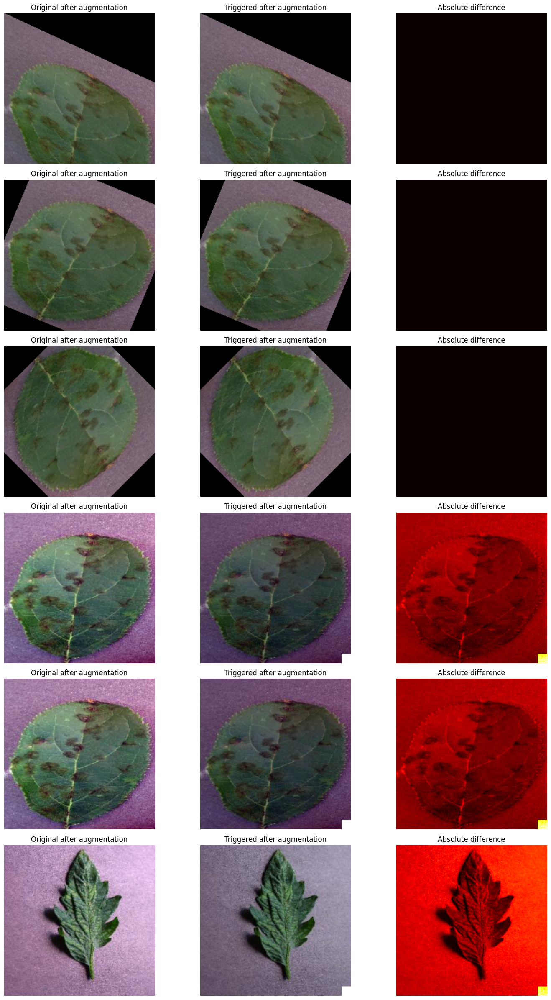

In [15]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


NEAR_ZERO_THRESHOLD = 1e-8
NUM_NEAR_ZERO = 3
NUM_HIGH = 3

# ImageNet normalization used by MobileNetV2
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]

near_zero_df = augmentation_df[
    augmentation_df["Mean Absolute Difference"] <= NEAR_ZERO_THRESHOLD
].head(NUM_NEAR_ZERO)

high_df = augmentation_df.sort_values(
    "Changed Pixel Ratio",
    ascending=False
).head(NUM_HIGH)

selected_df = pd.concat([
    near_zero_df.assign(Category="Near-zero"),
    high_df.assign(Category="High-impact")
]).drop_duplicates(
    subset=["Image", "Trial"]
).reset_index(drop=True)

print(f"Selected cases: {len(selected_df)}")

display(
    selected_df[
        [
            "Image",
            "Label",
            "Trial",
            "Changed Pixel Ratio",
            "Mean Absolute Difference",
            "Category"
        ]
    ]
)


def tensor_to_display(tensor):
    image = tensor.detach().cpu().float().clone()

    mean = torch.tensor(
        NORMALIZE_MEAN
    ).view(3, 1, 1)

    std = torch.tensor(
        NORMALIZE_STD
    ).view(3, 1, 1)

    image = image * std + mean
    image = image.clamp(0, 1)

    return image.permute(1, 2, 0).numpy()


def visualize_case(row, position, axes):

    # Find the original image using its filename
    matched = sample_df[
        sample_df["rel_path"].apply(
            lambda x: Path(x).name == row["Image"]
        )
    ]

    if matched.empty:
        raise ValueError(f"Cannot find image: {row['Image']}")

    image_path = matched.iloc[0]["image_path"]

    original = Image.open(image_path).convert("RGB")
    triggered = apply_trigger(original.copy())

    # Reproduce the same augmentation using the same seed
    seed = RANDOM_SEED + int(row["Trial"]) - 1

    original_tensor, triggered_tensor = transform_pair(
        original,
        triggered,
        seed
    )

    # Absolute difference
    diff = (
        triggered_tensor.float() - original_tensor.float()
    ).abs()

    # Display difference, normalized for visibility
    diff_display = diff.max(dim=0).values.numpy()

    if diff_display.max() > 0:
        diff_display = diff_display / diff_display.max()

    axes[position, 0].imshow(
        tensor_to_display(original_tensor)
    )
    axes[position, 0].set_title("Original after augmentation")

    axes[position, 1].imshow(
        tensor_to_display(triggered_tensor)
    )
    axes[position, 1].set_title("Triggered after augmentation")

    axes[position, 2].imshow(
        diff_display,
        cmap="hot",
        vmin=0,
        vmax=1
    )
    axes[position, 2].set_title("Absolute difference")

    for col in range(3):
        axes[position, col].axis("off")

    axes[position, 0].set_ylabel(
        f"{row['Category']}\n"
        f"Image: {row['Image'][:20]}...\n"
        f"Trial: {row['Trial']}\n"
        f"Changed ratio: {row['Changed Pixel Ratio']:.4f}",
        fontsize=9
    )


if len(selected_df) == 0:
    print("No cases selected.")
else:
    fig, axes = plt.subplots(
        len(selected_df),
        3,
        figsize=(15, 4 * len(selected_df)),
        squeeze=False
    )

    for i, (_, row) in enumerate(selected_df.iterrows()):
        visualize_case(row, i, axes)

    plt.tight_layout()
    plt.show()


### Nghi ngờ về ảnh hưởng của augmentation

Để kiểm tra trigger có còn hiện diện sau preprocessing hay không, cùng một augmentation ngẫu nhiên được áp dụng cho cặp ảnh gốc và ảnh đã chèn trigger. Seed được đặt lại trước mỗi lần transform để hai ảnh nhận cùng phép biến đổi ngẫu nhiên.

Với 38 ảnh và 30 lần thử cho mỗi ảnh (1,140 cặp):

- Mean Changed Pixel Ratio: 0.1030; median: 0.004464.
- Mean Absolute Difference: 0.03051; median: 0.006464.
- 304/1,140 trường hợp (26.67%) có Mean Absolute Difference gần bằng 0.

Kiểm tra trực quan một số trường hợp cho thấy có trường hợp trigger bị mất sau phép biến đổi (ví dụ phép xoay), trong khi một số trường hợp khác trigger bị thay đổi màu sắc.

**Nhận xét:** `TrivialAugmentWide` có thể làm biến dạng hoặc loại bỏ trigger trong một phần các lần augmentation. Đây là một yếu tố có khả năng ảnh hưởng đến backdoor learning. Tuy nhiên, kết quả này chưa chứng minh augmentation là nguyên nhân duy nhất khiến ASR thấp.


## Phân tích bổ sung: Post-augmentation pilot

Sau khi quan sát trigger có thể bị ảnh hưởng bởi augmentation, một pilot được thực hiện để kiểm tra giả thuyết này. Trong pilot, trigger được áp dụng **sau Resize và TrivialAugmentWide** ở training; ở ASR evaluation, trigger được áp dụng sau Resize.

Pilot sử dụng poisoning rate 10%, trigger trắng 16×16 ở góc dưới bên phải, target label 10, cùng dataset scope và cấu hình huấn luyện chính của E-BD1 (3 epochs, MobileNetV2 đóng băng backbone).

### Kết quả pilot

| Metric | E-BD1 ban đầu (10%) | Post-augmentation pilot |
|---|---:|---:|
| Clean Accuracy | 90.94% | 91.67% |
| Macro Precision | 90.49% | 90.96% |
| Macro Recall | 87.38% | 89.88% |
| Macro F1 | 87.91% | 89.66% |
| ASR | 2.78% | 0.90% |

Pilot có Clean Accuracy và Macro F1 cao hơn một chút, nhưng ASR giảm từ 2.78% xuống 0.90%. Vì vậy, việc bảo đảm trigger được chèn sau augmentation **không giúp cải thiện hiệu quả tấn công** trong cấu hình pilot này.

### Kiểm tra bổ sung từ pilot

- Training set có 13,028 mẫu, trong đó 1,275 mẫu poisoned (khoảng 9.78% tổng training set); tất cả poisoned samples mang label 10.
- Target class có 279 mẫu gốc và 1,275 poisoned samples, tổng cộng 1,554 mẫu.
- ASR evaluation có 10,643 ảnh thuộc các lớp non-target.
- Trigger được quan sát thấy trên ảnh sau preprocessing của training.
- Model dự đoán target label 10 cho 96/10,643 ảnh có trigger, tương ứng ASR 0.902%.
- Clean test target-class recall đạt 97.42%.

Các kiểm tra này cho thấy nhãn poisoning, tập ASR và thao tác chèn trigger trong pilot có cấu trúc phù hợp với thiết kế. Model cũng nhận diện tốt ảnh sạch thuộc target class, nhưng vẫn hiếm khi dự đoán target label cho ảnh non-target có trigger.

### Diễn giải

Trong cấu hình được khảo sát, model vẫn phân loại ảnh sạch tương đối tốt và nhận diện được target class, nhưng chưa học được mối liên hệ đủ mạnh giữa trigger và target label để tạo ra ASR cao.

Kết quả pilot không ủng hộ giả thuyết rằng chỉ cần chuyển thao tác chèn trigger xuống sau augmentation là có thể khắc phục ASR thấp. Do đó, ảnh hưởng của augmentation có thể là một yếu tố, nhưng không phải lời giải đầy đủ cho hiện tượng quan sát được.

Lưu ý: pilot là phân tích bổ sung với một lần chạy, không thay thế hoặc ghi đè kết quả E-BD1 ban đầu.


## Kết luận E-BD1 và định hướng thí nghiệm tiếp theo

E-BD1 cho thấy poisoning rate có ảnh hưởng rõ rệt đến cả attack effectiveness và clean performance. Khi poisoning rate tăng, ASR tăng nhưng Clean Accuracy và Macro F1 suy giảm đáng kể. Ngay cả ở poisoning rate 40%, ASR mới đạt 35.21%, cho thấy backdoor attack chưa đạt hiệu quả cao trong cấu hình hiện tại.

Phân tích trigger cho thấy trigger có khác biệt pixel rõ ràng trên ảnh gốc, nhưng augmentation có thể làm thay đổi hoặc loại bỏ trigger trong một số trường hợp. Tuy nhiên, post-augmentation pilot cho thấy việc chèn trigger sau augmentation chưa cải thiện ASR. Vì vậy, chưa đủ cơ sở để quy nguyên nhân ASR thấp chỉ cho augmentation hoặc khẳng định model hoàn toàn không nhận ra trigger.

**Kết luận phù hợp:** Trong các cấu hình được khảo sát, mô hình chưa học được mối liên hệ đủ mạnh giữa trigger và target label. Tăng poisoning rate giúp tăng ASR nhưng đồng thời làm suy giảm hiệu quả phân loại trên dữ liệu sạch.

### Chuyển tiếp sang E-BD2

E-BD2 tiếp tục khảo sát ảnh hưởng của **trigger size** đến hiệu quả backdoor attack. Giữ nguyên dataset, target label, trigger position, model và training configuration; chỉ thay đổi kích thước trigger theo các variant đã định nghĩa trong file cấu hình.

Kết quả post-augmentation pilot được giữ lại như phân tích bổ sung; pipeline thí nghiệm chính của E-BD2 tiếp tục sử dụng cách triển khai trigger thống nhất với pipeline E-BD1 để bảo đảm khả năng so sánh giữa các experiment.


In [ ]:
# E-BD2: trigger_size_sweep
%cd /content/data-poisoning-plantvillage
run_backdoor_experiment('E-BD2')


In [ ]:
# E-BD3: trigger_position_sweep
%cd /content/data-poisoning-plantvillage
run_backdoor_experiment('E-BD3')


In [ ]:
# E-BD4: representative_rate_confirmation
%cd /content/data-poisoning-plantvillage
run_backdoor_experiment('E-BD4')


In [ ]:
# Xem kết quả backdoor đã có trên Drive
_rows = []
for _p in sorted((DRIVE_RESULTS / 'backdoor').glob('*/results/**/metrics.json')):
    _m = json.loads(_p.read_text(encoding='utf-8'))
    _meta = _m['run_metadata']
    _row = {'experiment': _meta['experiment_id'], 'rate': _meta['poisoning_rate'],
            'size_px': _meta['trigger_size_px'], 'position': _meta['trigger_position'],
            'seed': _meta['run_seed'], 'epochs': _meta['epochs'], 'train': _meta['train_samples']}
    _row.update({f'clean_{k}': v for k, v in _m['clean']['metrics'].items() if isinstance(v, (int, float))})
    _row.update({f'bd_{k}': v for k, v in _m['backdoor']['metrics'].items() if isinstance(v, (int, float))})
    _rows.append(_row)

if _rows:
    _df = pd.DataFrame(_rows).sort_values(['experiment', 'rate', 'size_px', 'position', 'seed']).reset_index(drop=True)
    display(_df)
    _metric_cols = [c for c in _df.columns if c.startswith(('clean_', 'bd_'))]
    display(_df.groupby(['experiment', 'rate', 'size_px', 'position'])[_metric_cols].agg(['mean', 'std']))
else:
    print('Chưa có kết quả nào.')


In [ ]:
# Chạy khi kết thúc phiên (sau khi đã xem xong kết quả). Sau lệnh này Drive bị ngắt:
# muốn chạy tiếp phải chạy lại cell mount (hoặc khởi động lại runtime).
finish_session()